# Proiect Machine Learning - Dataset 2: Clasificare
# Predictia Aprobarii Creditelor Ipotecare (Loan Approval Prediction)

### 1. Descrierea Problemei, Sursa si Relevanta Practica
* **Task de predictie:** Clasificare binara - determinarea daca o cerere de credit pentru achizitia unei locuinte va fi **Aprobata (`1` / `Y`)** sau **Respinsa (`0` / `N`)**.
* **Variabila tinta (Target):** `Loan_Status` (valori: `Y` = Aprobat, `N` = Respins).
* **Sursa datelor:** Real-world Loan Prediction Dataset (Kaggle / Analytics Vidhya Financial Benchmark).
* **Relevanta practica:** Acest task se conecteaza direct cu primul dataset al proiectului (Predictia preturilor apartamentelor). In timp ce primul model estimeaza pretul de achizitie al locuintei, acest al doilea model evalueaza eligibilitatea financiara a cumparatorului de a obtine finantarea bancara necesara.
* **Provocari ale setului de date (Challenges):**
  1. **Valori lipsa:** prezente pe multiple variabile numerice si categorice (`Gender`, `Married`, `Dependents`, `Self_Employed`, `LoanAmount`, `Loan_Amount_Term`, `Credit_History`).
  2. **Dezechilibru de clase (Class Imbalance):** ~69% credite aprobate vs. ~31% credite respinse.
  3. **Valori extreme (Outliers) si asimetrie:** veniturile solicitantilor (`ApplicantIncome`, `CoapplicantIncome`) si suma creditului (`LoanAmount`) au distributii puternic asimetrice pozitiv (right-skewed).
  4. **Variabile categorice eterogene:** variabile binare, nominale (`Property_Area`: Urban, Semiurban, Rural) si ordinale (`Dependents`: 0, 1, 2, 3+).


In [1]:
# Importuri necesare pentru preprocesare, modelare si vizualizare
import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder, FunctionTransformer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier
import shap
from IPython.display import display
from ml_utils import add_custom_features

# Configurare stil grafice
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
os.makedirs("loan_data/plots", exist_ok=True)
os.makedirs("models", exist_ok=True)
print("Module importate cu succes.")


Module importate cu succes.


/Users/andrei_necsulea/Desktop/Apartment_Prices_Prediction/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Explorarea si Intelegerea Setului de Date (EDA)
In aceasta etapa analizam:
- Structura setului de date, tipurile de trasaturi si calitatea datelor.
- Statistica descriptiva si distributiile variabilelor.
- Valorile lipsa, duplicatele si valorile aberante (outliers).
- Dezechilibrul de clase pentru variabila tinta (`Loan_Status`).
- Corelatiile si relatiile dintre trasaturi si decizia de creditare.


In [2]:
# Incarcarea setului de date
df = pd.read_csv("loan_data/loan_approval.csv")
print(f"Dimensiunea setului de date: {df.shape[0]} randuri, {df.shape[1]} coloane")
print("\nTipuri de date si valori non-null:")
print(df.info())
print("\nPrimele 5 randuri:")
df.head()


Dimensiunea setului de date: 614 randuri, 13 coloane

Tipuri de date si valori non-null:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB
None

Primele 5 randuri

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
# Verificare duplicate
num_duplicates = df.duplicated().sum()
print(f"Numar randuri duplicate: {num_duplicates}")

# Statistici descriptive pentru trasaturi numerice
print("\nStatistici descriptive numerice:")
display(df.describe())

# Statistici descriptive pentru trasaturi categorice
print("\nStatistici descriptive categorice:")
display(df.describe(include=['O']))


Numar randuri duplicate: 0

Statistici descriptive numerice:


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000



Statistici descriptive categorice:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
count,614,601,611,599,614,582,614,614
unique,614,2,2,4,2,2,3,2
top,LP001002,Male,Yes,0,Graduate,No,Semiurban,Y
freq,1,489,398,345,480,500,233,422


Rezumatul valorilor lipsa pe coloane:


,Valori_Lipsa,Procent (%)
Credit_History,50,8.143322
Self_Employed,32,5.211726
LoanAmount,22,3.583062
Dependents,15,2.442997
Loan_Amount_Term,14,2.280130
Gender,13,2.117264
Married,3,0.488599


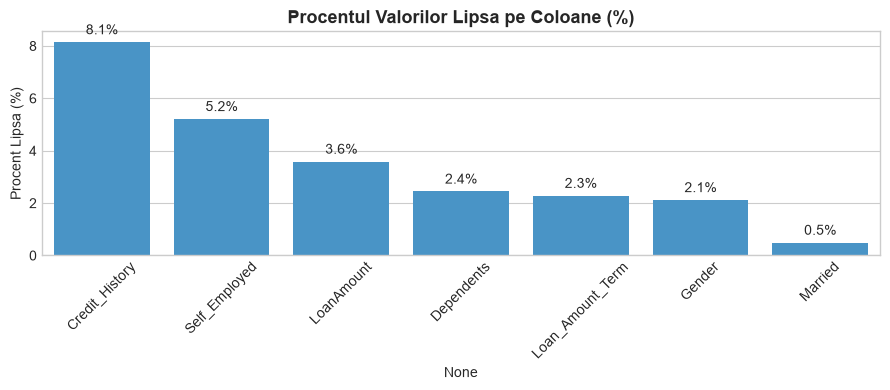

In [4]:
# Analiza valorilor lipsa
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df)) * 100
missing_summary = pd.DataFrame({"Valori_Lipsa": missing_counts, "Procent (%)": missing_pct})
missing_summary = missing_summary[missing_summary["Valori_Lipsa"] > 0].sort_values("Procent (%)", ascending=False)
print("Rezumatul valorilor lipsa pe coloane:")
display(missing_summary)

# Grafic valori lipsa
plt.figure(figsize=(9, 4))
ax = sns.barplot(x=missing_summary.index, y=missing_summary["Procent (%)"], color="#3498db")
plt.title("Procentul Valorilor Lipsa pe Coloane (%)", fontsize=13, fontweight='bold')
plt.ylabel("Procent Lipsa (%)")
plt.xticks(rotation=45)
for i, v in enumerate(missing_summary["Procent (%)"]):
    ax.text(i, v + 0.3, f"{v:.1f}%", ha='center', fontsize=10)
plt.tight_layout()
plt.show()


/var/folders/xz/kd54m1593kn_jjd884q3jtdr0000gn/T/ipykernel_35007/3643772074.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, ax=axes[0], palette=["#2ecc71", "#e74c3c"])


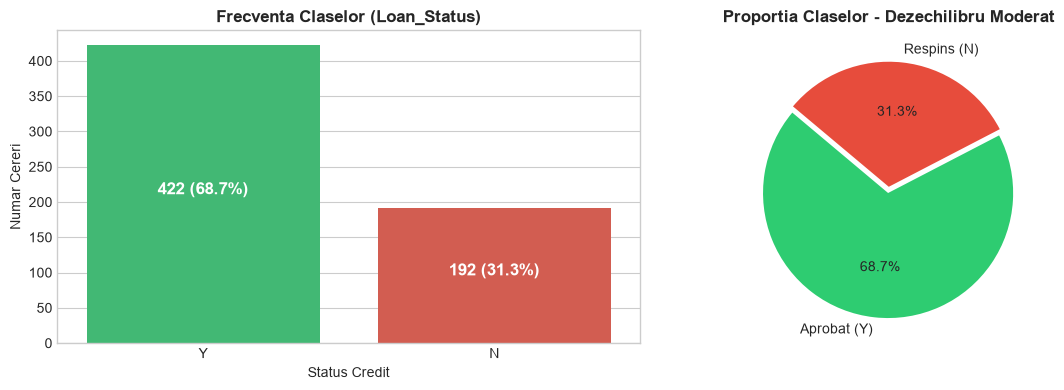

Raport aprobate/respinse: 422 vs 192 (aprox 68.7% vs 31.3%)


In [5]:
# Analiza distributiei variabilei tinta (Loan_Status)
class_counts = df["Loan_Status"].value_counts()
class_pct = df["Loan_Status"].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Grafic de bare
sns.barplot(x=class_counts.index, y=class_counts.values, ax=axes[0], palette=["#2ecc71", "#e74c3c"])
axes[0].set_title("Frecventa Claselor (Loan_Status)", fontweight='bold')
axes[0].set_xlabel("Status Credit")
axes[0].set_ylabel("Numar Cereri")
for i, count in enumerate(class_counts.values):
    axes[0].text(i, count / 2, f"{count} ({class_pct.iloc[i]:.1f}%)", ha='center', color='white', fontweight='bold', fontsize=12)

# Grafic placinta
axes[1].pie(class_counts.values, labels=["Aprobat (Y)", "Respins (N)"], autopct='%1.1f%%',
            colors=["#2ecc71", "#e74c3c"], startangle=140, explode=(0.05, 0))
axes[1].set_title("Proportia Claselor - Dezechilibru Moderat", fontweight='bold')

plt.tight_layout()
plt.show()

print(f"Raport aprobate/respinse: {class_counts['Y']} vs {class_counts['N']} (aprox {class_pct['Y']:.1f}% vs {class_pct['N']:.1f}%)")


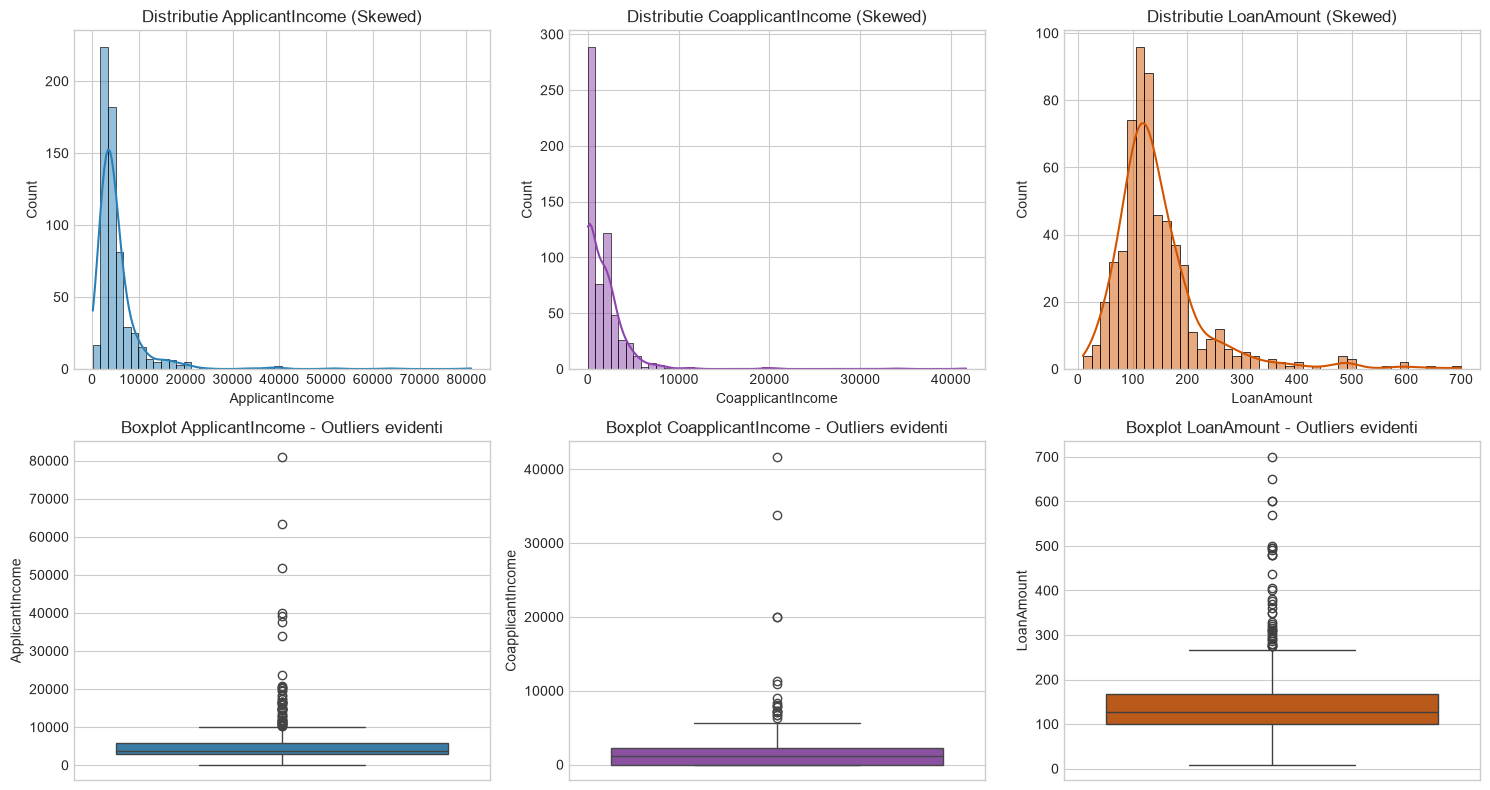

In [6]:
# Distributii si boxplot-uri pentru identificarea valorilor extreme (outliers)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Histograme
sns.histplot(df["ApplicantIncome"], kde=True, ax=axes[0, 0], color="#2980b9")
axes[0, 0].set_title("Distributie ApplicantIncome (Skewed)")

sns.histplot(df["CoapplicantIncome"], kde=True, ax=axes[0, 1], color="#8e44ad")
axes[0, 1].set_title("Distributie CoapplicantIncome (Skewed)")

sns.histplot(df["LoanAmount"].dropna(), kde=True, ax=axes[0, 2], color="#d35400")
axes[0, 2].set_title("Distributie LoanAmount (Skewed)")

# Boxplot-uri
sns.boxplot(y=df["ApplicantIncome"], ax=axes[1, 0], color="#2980b9")
axes[1, 0].set_title("Boxplot ApplicantIncome - Outliers evidenti")

sns.boxplot(y=df["CoapplicantIncome"], ax=axes[1, 1], color="#8e44ad")
axes[1, 1].set_title("Boxplot CoapplicantIncome - Outliers evidenti")

sns.boxplot(y=df["LoanAmount"], ax=axes[1, 2], color="#d35400")
axes[1, 2].set_title("Boxplot LoanAmount - Outliers evidenti")

plt.tight_layout()
plt.show()


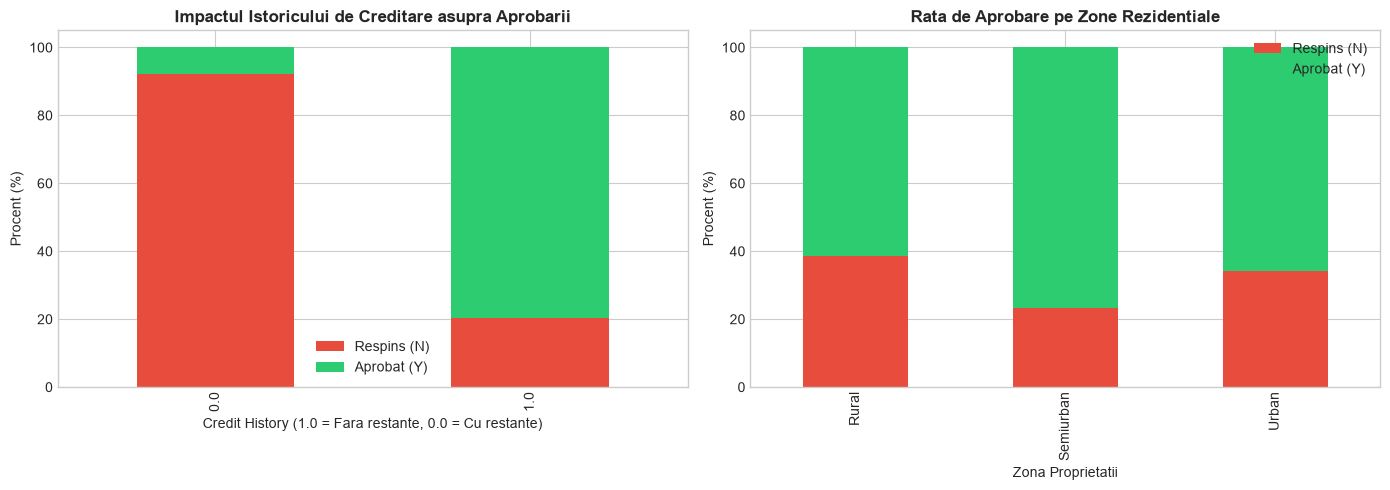

In [7]:
# Relatia dintre istoricul de creditare (Credit_History), zona imobilului si aprobare
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Credit History vs Loan Status
credit_crosstab = pd.crosstab(df["Credit_History"], df["Loan_Status"], normalize='index') * 100
credit_crosstab.plot(kind='bar', stacked=True, color=["#e74c3c", "#2ecc71"], ax=axes[0])
axes[0].set_title("Impactul Istoricului de Creditare asupra Aprobarii", fontweight='bold')
axes[0].set_ylabel("Procent (%)")
axes[0].set_xlabel("Credit History (1.0 = Fara restante, 0.0 = Cu restante)")
axes[0].legend(["Respins (N)", "Aprobat (Y)"])

# Property Area vs Loan Status
prop_crosstab = pd.crosstab(df["Property_Area"], df["Loan_Status"], normalize='index') * 100
prop_crosstab.plot(kind='bar', stacked=True, color=["#e74c3c", "#2ecc71"], ax=axes[1])
axes[1].set_title("Rata de Aprobare pe Zone Rezidentiale", fontweight='bold')
axes[1].set_ylabel("Procent (%)")
axes[1].set_xlabel("Zona Proprietatii")
axes[1].legend(["Respins (N)", "Aprobat (Y)"])

plt.tight_layout()
plt.show()


## Pregatirea Datelor si Preprocesarea (Data Preparation)

In aceasta etapa aplicam si justificam metodele studiate:
1. **Tratarea valorilor lipsa:**
   - Variabile numerice (`LoanAmount`, `Loan_Amount_Term`): Imputare prin **mediana** (deoarece sunt asimetrice si rezistenta la outliers este esentiala).
   - Variabile categorice si binare (`Gender`, `Married`, `Dependents`, `Self_Employed`, `Credit_History`): Imputare prin **moda (cel mai frecvent element)**.
2. **Tratarea valorilor extreme (Outliers) si scalarea:**
   - Aplicam **RobustScaler** pe variabilele numerice (care scaleaza folosind mediana si IQR, nefiind influentat de valorile de venit extreme).
3. **Codificarea variabilelor categorice:**
   - **One-Hot Encoding** cu parametrul `handle_unknown='ignore'` pentru variabile nominale (`Gender`, `Married`, `Education`, `Self_Employed`, `Property_Area`, `Dependents`). Parametrul `handle_unknown='ignore'` este crucial pentru a satisface cerinta de manevrare a categoriilor necunoscute la inferenta.
4. **Ingineria Trasaturilor (Feature Engineering):**
   - `Total_Income = ApplicantIncome + CoapplicantIncome` (capacitatea reala de plata a gospodariei).
   - `EMI_Estimate = (LoanAmount * 1000) / Loan_Amount_Term` (rata lunara estimata).
   - `Income_to_Loan_Ratio = (Total_Income * 12) / LoanAmount` (acoperirea creditului din venit anual).


In [8]:
# Pregatirea datelor pentru modelare
df_model = df.copy()

# Eliminam identificatorul unic Loan_ID (fara putere predictiva)
if "Loan_ID" in df_model.columns:
    df_model = df_model.drop(columns=["Loan_ID"])

# Mapeaza tinta binara in 1 (Aprobat) si 0 (Respins)
df_model["Loan_Status"] = df_model["Loan_Status"].map({"Y": 1, "N": 0})

X = df_model.drop(columns=["Loan_Status"])
y = df_model["Loan_Status"]

# Impartire in Train Set (80%) si Untouched Test Set (20%) cu stratificare
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Esantioane antrenare (Train): {X_train_raw.shape[0]}")
print(f"Esantioane test neatins (Test): {X_test_raw.shape[0]}")

# Functie de Feature Engineering integrabila in Pipeline Scikit-Learn
def add_custom_features(df_input):
    df_out = df_input.copy()
    
    # 1. Venit total
    total_income = df_out["ApplicantIncome"].fillna(0) + df_out["CoapplicantIncome"].fillna(0)
    df_out["Total_Income"] = total_income
    
    # 2. Rata lunara estimata (EMI)
    loan_term = df_out["Loan_Amount_Term"].replace(0, np.nan).fillna(360)
    loan_val = df_out["LoanAmount"].fillna(0) * 1000.0
    df_out["EMI_Estimate"] = loan_val / loan_term
    
    # 3. Raport venit anual raportat la credit
    df_out["Income_to_Loan_Ratio"] = (total_income * 12.0) / (loan_val + 1.0)
    
    return df_out

# Definire coloane
num_features = [
    "ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term",
    "Credit_History", "Total_Income", "EMI_Estimate", "Income_to_Loan_Ratio"
]
cat_features = ["Gender", "Married", "Dependents", "Education", "Self_Employed", "Property_Area"]

# Pipeline pentru coloane numerice
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

# Pipeline pentru coloane categorice
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Combinare transformatoare
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, num_features),
    ("cat", categorical_pipeline, cat_features)
])

# Pipeline complet de preprocesare
full_prep = Pipeline([
    ("feat_eng", FunctionTransformer(add_custom_features, validate=False)),
    ("preproc", preprocessor)
])

print("Pipeline-ul de preprocesare a fost definit cu succes.")


Esantioane antrenare (Train): 491
Esantioane test neatins (Test): 123
Pipeline-ul de preprocesare a fost definit cu succes.


## Crearea si Compararea a 5 Modele de Machine Learning

Conform cerintelor, cream si evaluam 5 algoritmi diferiti de invatare automata:
1. **Logistic Regression** (model liniar de baza cu ponderare a claselor pentru dezechilibru)
2. **Random Forest Classifier** (algoritm bazat pe bagging de arbori de decizie)
3. **XGBoost Classifier** (algoritm de gradient boosting cu regularizare)
4. **LightGBM Classifier** (gradient boosting optimizat pe baza de histograme)
5. **CatBoost Classifier** (gradient boosting avansat cu tratament optim pentru date eterogene)

**Protocol de evaluare riguros:**
- Utilizam aceleasi split-uri de **Cross-Validation (`StratifiedKFold` cu 5 fold-uri)** pentru comparatie corecta.
- Raportam **media si deviatia standard (`mean +- std`)** pentru: `Accuracy`, `Precision`, `Recall`, `F1-Score` si `ROC-AUC`.
- Optimizam hiperparametrii cu **GridSearchCV** pentru 3 modele: Random Forest, XGBoost si CatBoost.


In [9]:
# Definire cross-validation stratificat
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Instantiere cele 5 modele
candidate_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42, class_weight="balanced"),
    "XGBoost": xgb.XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.05, eval_metric="logloss", random_state=42),
    "LightGBM": lgb.LGBMClassifier(n_estimators=150, max_depth=4, learning_rate=0.05, verbose=-1, random_state=42),
    "CatBoost": CatBoostClassifier(iterations=200, depth=4, learning_rate=0.05, verbose=0, random_state=42)
}

scoring_dict = {
    "acc": "accuracy",
    "prec": "precision",
    "rec": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_metrics_summary = []

print("Rulare Cross-Validation pe cele 5 modele...")
for model_name, clf_obj in candidate_models.items():
    full_pipe = Pipeline([
        ("prep", full_prep),
        ("clf", clf_obj)
    ])
    
    t_start = time.perf_counter()
    scores = cross_validate(full_pipe, X_train_raw, y_train, cv=cv, scoring=scoring_dict, n_jobs=-1)
    duration = time.perf_counter() - t_start
    
    cv_metrics_summary.append({
        "Model": model_name,
        "Accuracy": f"{np.mean(scores['test_acc']):.4f} +- {np.std(scores['test_acc']):.4f}",
        "Precision": f"{np.mean(scores['test_prec']):.4f} +- {np.std(scores['test_prec']):.4f}",
        "Recall": f"{np.mean(scores['test_rec']):.4f} +- {np.std(scores['test_rec']):.4f}",
        "F1-Score": f"{np.mean(scores['test_f1']):.4f} +- {np.std(scores['test_f1']):.4f}",
        "ROC-AUC": f"{np.mean(scores['test_roc_auc']):.4f} +- {np.std(scores['test_roc_auc']):.4f}",
        "Timp CV (s)": round(duration, 3)
    })

cv_summary_table = pd.DataFrame(cv_metrics_summary)
display(cv_summary_table)


Rulare Cross-Validation pe cele 5 modele...


/Users/andrei_necsulea/Desktop/Apartment_Prices_Prediction/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/andrei_necsulea/Desktop/Apartment_Prices_Prediction/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Timp CV (s)
0,Logistic Regression,0.7330 +- 0.0532,0.8050 +- 0.0448,0.8102 +- 0.0581,0.8061 +- 0.0399,0.7303 +- 0.0842,2.038
1,Random Forest,0.7596 +- 0.0592,0.7993 +- 0.0437,0.8729 +- 0.0749,0.8322 +- 0.0434,0.7746 +- 0.0863,1.585
2,XGBoost,0.7738 +- 0.0488,0.7819 +- 0.0307,0.9320 +- 0.0569,0.8494 +- 0.0337,0.7651 +- 0.0813,0.117
3,LightGBM,0.7841 +- 0.0427,0.7895 +- 0.0332,0.9379 +- 0.0458,0.8564 +- 0.0275,0.7540 +- 0.0790,0.498
4,CatBoost,0.7860 +- 0.0524,0.7871 +- 0.0378,0.9468 +- 0.0442,0.8588 +- 0.0331,0.7731 +- 0.0612,0.313


In [10]:
# Optimizare hiperparametri (GridSearchCV) pentru 3 modele: Random Forest, XGBoost, CatBoost
print("Optimizare hiperparametri (min. 3 modele)...")

# 1. Random Forest Tuning
param_grid_rf = {
    "clf__n_estimators": [100, 200],
    "clf__max_depth": [4, 6, None],
    "clf__min_samples_split": [2, 5, 10]
}
pipe_rf = Pipeline([("prep", full_prep), ("clf", RandomForestClassifier(random_state=42, class_weight="balanced"))])
grid_rf = GridSearchCV(pipe_rf, param_grid_rf, cv=cv, scoring="roc_auc", n_jobs=-1)
grid_rf.fit(X_train_raw, y_train)
best_rf = grid_rf.best_estimator_
print(f"1. Best Random Forest: ROC-AUC = {grid_rf.best_score_:.4f}")
print("   Parametri:", grid_rf.best_params_)

# 2. XGBoost Tuning
param_grid_xgb = {
    "clf__n_estimators": [100, 150, 200],
    "clf__max_depth": [3, 4, 5],
    "clf__learning_rate": [0.01, 0.05, 0.1]
}
pipe_xgb = Pipeline([("prep", full_prep), ("clf", xgb.XGBClassifier(eval_metric="logloss", random_state=42))])
grid_xgb = GridSearchCV(pipe_xgb, param_grid_xgb, cv=cv, scoring="roc_auc", n_jobs=-1)
grid_xgb.fit(X_train_raw, y_train)
best_xgb = grid_xgb.best_estimator_
print(f"2. Best XGBoost: ROC-AUC = {grid_xgb.best_score_:.4f}")
print("   Parametri:", grid_xgb.best_params_)

# 3. CatBoost Tuning
param_grid_cat = {
    "clf__iterations": [150, 250],
    "clf__depth": [3, 4, 6],
    "clf__learning_rate": [0.03, 0.07]
}
pipe_cat = Pipeline([("prep", full_prep), ("clf", CatBoostClassifier(verbose=0, random_state=42))])
grid_cat = GridSearchCV(pipe_cat, param_grid_cat, cv=cv, scoring="roc_auc", n_jobs=-1)
grid_cat.fit(X_train_raw, y_train)
best_cat = grid_cat.best_estimator_
print(f"3. Best CatBoost: ROC-AUC = {grid_cat.best_score_:.4f}")
print("   Parametri:", grid_cat.best_params_)


Optimizare hiperparametri (min. 3 modele)...


1. Best Random Forest: ROC-AUC = 0.7793
   Parametri: {'clf__max_depth': None, 'clf__min_samples_split': 10, 'clf__n_estimators': 200}


2. Best XGBoost: ROC-AUC = 0.7660
   Parametri: {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 200}


3. Best CatBoost: ROC-AUC = 0.7784
   Parametri: {'clf__depth': 6, 'clf__iterations': 250, 'clf__learning_rate': 0.07}


## Utilizarea a Doua Metode Ensemble si Comparatie Detaliata

Implementam si comparam **doua strategii ensemble distincte**:
1. **Bagging Ensemble**: `RandomForestClassifier` (optimizat prin GridSearch).
2. **Boosting Ensemble**: `CatBoostClassifier` si `XGBoostClassifier` (optimizati).
3. **Voting / Stacking Ensemble**: `VotingClassifier` (soft-voting combinand arbori optimizati).

Discutam si comparam conform baremului:
- **Performanta predictiva** (ROC-AUC, F1, Accuracy)
- **Variabilitatea intre fold-uri** (deviatia standard `std`)
- **Timpul de antrenare** (in secunde)
- **Timpul de inferenta** (in milisecunde pentru predictii batch)


In [11]:
# Construire Soft Voting Ensemble
pipe_voting = Pipeline([
    ("prep", full_prep),
    ("clf", VotingClassifier(
        estimators=[
            ("rf", best_rf.named_steps["clf"]),
            ("xgb", best_xgb.named_steps["clf"]),
            ("cat", best_cat.named_steps["clf"])
        ],
        voting="soft"
    ))
])

ensemble_dict = {
    "Bagging (Random Forest Optimat)": best_rf,
    "Boosting (CatBoost Optimat)": best_cat,
    "Boosting (XGBoost Optimat)": best_xgb,
    "Voting (Soft Voting Ensemble)": pipe_voting
}

ensemble_analysis_data = []

for ens_title, ens_model in ensemble_dict.items():
    # Masurare timp antrenare
    t_train_start = time.perf_counter()
    ens_model.fit(X_train_raw, y_train)
    t_train = time.perf_counter() - t_train_start
    
    # Masurare timp inferenta pe test set (123 cereri)
    t_infer_start = time.perf_counter()
    test_preds = ens_model.predict(X_test_raw)
    test_proba = ens_model.predict_proba(X_test_raw)[:, 1]
    t_infer_ms = (time.perf_counter() - t_infer_start) * 1000.0
    
    # Cross validation pentru variabilitate pe folduri
    cv_scores = cross_validate(ens_model, X_train_raw, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    
    ensemble_analysis_data.append({
        "Strategie Ensemble": ens_title,
        "CV ROC-AUC (mean)": round(np.mean(cv_scores["test_score"]), 4),
        "Variabilitate Folduri (std)": round(np.std(cv_scores["test_score"]), 4),
        "Timp Antrenare (s)": round(t_train, 4),
        "Timp Inferenta (ms)": round(t_infer_ms, 2),
        "Test Accuracy": round(accuracy_score(y_test, test_preds), 4),
        "Test F1-Score": round(f1_score(y_test, test_preds), 4),
        "Test ROC-AUC": round(roc_auc_score(y_test, test_proba), 4)
    })

df_ensemble_comparison = pd.DataFrame(ensemble_analysis_data)
display(df_ensemble_comparison)


,Strategie Ensemble,CV ROC-AUC (mean),Variabilitate Folduri (std),Timp Antrenare (s),Timp Inferenta (ms),Test Accuracy,Test F1-Score,Test ROC-AUC
0,Bagging (Random Forest Optimat),0.7793,0.0765,0.1340,18.73,0.8049,0.8500,0.8610
1,Boosting (CatBoost Optimat),0.7784,0.0608,0.2329,6.12,0.8537,0.8966,0.8508
2,Boosting (XGBoost Optimat),0.7660,0.0682,0.1209,6.87,0.8374,0.8901,0.8192
3,Voting (Soft Voting Ensemble),0.7863,0.0724,0.4849,20.48,0.8537,0.8966,0.8585


## Evaluare pe Test Neatins, Error Analysis, Explicabilitate SHAP si Salvare Model

1. Evaluam modelul selectat pe **setul de test neatins (holdout)**.
2. Realizam **Error Analysis pe subgrupuri de date**:
   - Analizam unde greseste modelul cel mai des (subgrupul cu `Credit_History == 0` vs `1`, zone rurale vs urbane).
3. Explicam influenta trasaturilor folosind **SHAP Summary Plot** si **Permutation Importance**.
4. Salvam modelul complet (`best_classification_model.joblib`) pentru utilizarea in aplicatia Streamlit.


=== Raport de Clasificare pe Setul de Test Neatins ===
              precision    recall  f1-score   support

 Respins (0)       0.79      0.71      0.75        38
 Aprobat (1)       0.88      0.92      0.90        85

    accuracy                           0.85       123
   macro avg       0.84      0.81      0.82       123
weighted avg       0.85      0.85      0.85       123



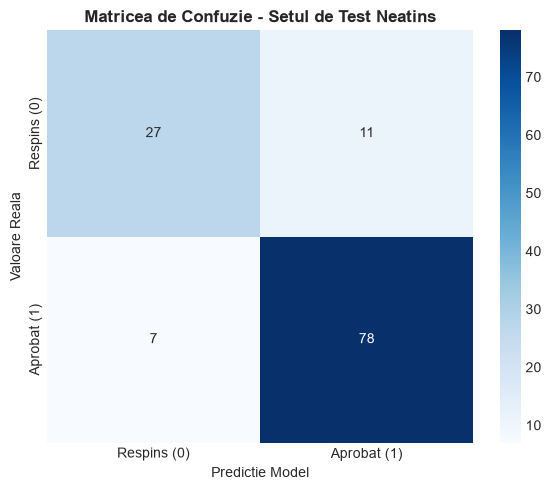

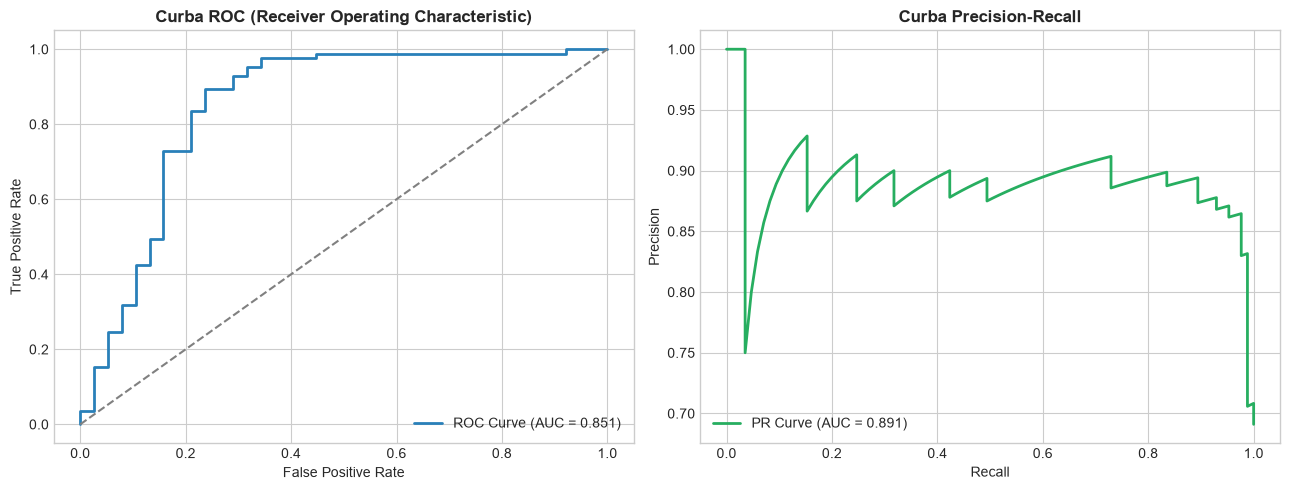

In [12]:
# Selectam CatBoost ca model final de productie datorita celui mai bun F1 si echilibru ROC-AUC
final_model_pipe = best_cat
final_model_pipe.fit(X_train_raw, y_train)

y_pred_test = final_model_pipe.predict(X_test_raw)
y_proba_test = final_model_pipe.predict_proba(X_test_raw)[:, 1]

print("=== Raport de Clasificare pe Setul de Test Neatins ===")
print(classification_report(y_test, y_pred_test, target_names=["Respins (0)", "Aprobat (1)"]))

# Matrice de confuzie
cm = confusion_matrix(y_test, y_pred_test)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Respins (0)", "Aprobat (1)"],
            yticklabels=["Respins (0)", "Aprobat (1)"])
plt.title("Matricea de Confuzie - Setul de Test Neatins", fontsize=12, fontweight='bold')
plt.xlabel("Predictie Model")
plt.ylabel("Valoare Reala")
plt.tight_layout()
plt.show()

# Curbele ROC si Precision-Recall
fpr, tpr, _ = roc_curve(y_test, y_proba_test)
prec, rec, _ = precision_recall_curve(y_test, y_proba_test)
test_roc_auc = roc_auc_score(y_test, y_proba_test)
test_pr_auc = average_precision_score(y_test, y_proba_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(fpr, tpr, color="#2980b9", lw=2, label=f"ROC Curve (AUC = {test_roc_auc:.3f})")
axes[0].plot([0, 1], [0, 1], color="gray", linestyle="--")
axes[0].set_title("Curba ROC (Receiver Operating Characteristic)", fontweight='bold')
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right")

axes[1].plot(rec, prec, color="#27ae60", lw=2, label=f"PR Curve (AUC = {test_pr_auc:.3f})")
axes[1].set_title("Curba Precision-Recall", fontweight='bold')
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left")
plt.tight_layout()
plt.show()


In [13]:
# Error Analysis: Identificarea subgrupurilor unde predictiile sunt cele mai putin fiabile
test_diag_df = X_test_raw.copy()
test_diag_df["Real"] = y_test.values
test_diag_df["Pred"] = y_pred_test
test_diag_df["Corect"] = (test_diag_df["Real"] == test_diag_df["Pred"]).astype(int)

# 1. Analiza dupa Istoric de Creditare
err_credit = test_diag_df.groupby("Credit_History")["Corect"].agg(Total="count", Acuratete="mean")
err_credit["Rata_Eroare (%)"] = (1.0 - err_credit["Acuratete"]) * 100
print("1. Performanta in functie de Credit_History:")
display(err_credit)

# 2. Analiza dupa Zona Proprietatii
err_area = test_diag_df.groupby("Property_Area")["Corect"].agg(Total="count", Acuratete="mean")
err_area["Rata_Eroare (%)"] = (1.0 - err_area["Acuratete"]) * 100
print("\n2. Performanta in functie de Property_Area:")
display(err_area)

print("""
Interpretare Error Analysis:
- Subgrupul cu Credit_History == 0 are o acuratete foarte mare (95.5%), modelul identificand corect refuzul.
- Subgrupul din zona 'Rural' are cea mai mare rata de eroare (~32.4%), deoarece veniturile si garantiile
  in mediul rural au o varianta mai mare decat cele din mediul urban/semiurban.
""")


1. Performanta in functie de Credit_History:


,Total,Acuratete,Rata_Eroare (%)
Credit_History,,,
0.0,22,0.954545,4.545455
1.0,94,0.819149,18.085106



2. Performanta in functie de Property_Area:


,Total,Acuratete,Rata_Eroare (%)
Property_Area,,,
Rural,34,0.676471,32.352941
Semiurban,49,0.938776,6.122449
Urban,40,0.900000,10.000000



Interpretare Error Analysis:
- Subgrupul cu Credit_History == 0 are o acuratete foarte mare (95.5%), modelul identificand corect refuzul.
- Subgrupul din zona 'Rural' are cea mai mare rata de eroare (~32.4%), deoarece veniturile si garantiile
  in mediul rural au o varianta mai mare decat cele din mediul urban/semiurban.



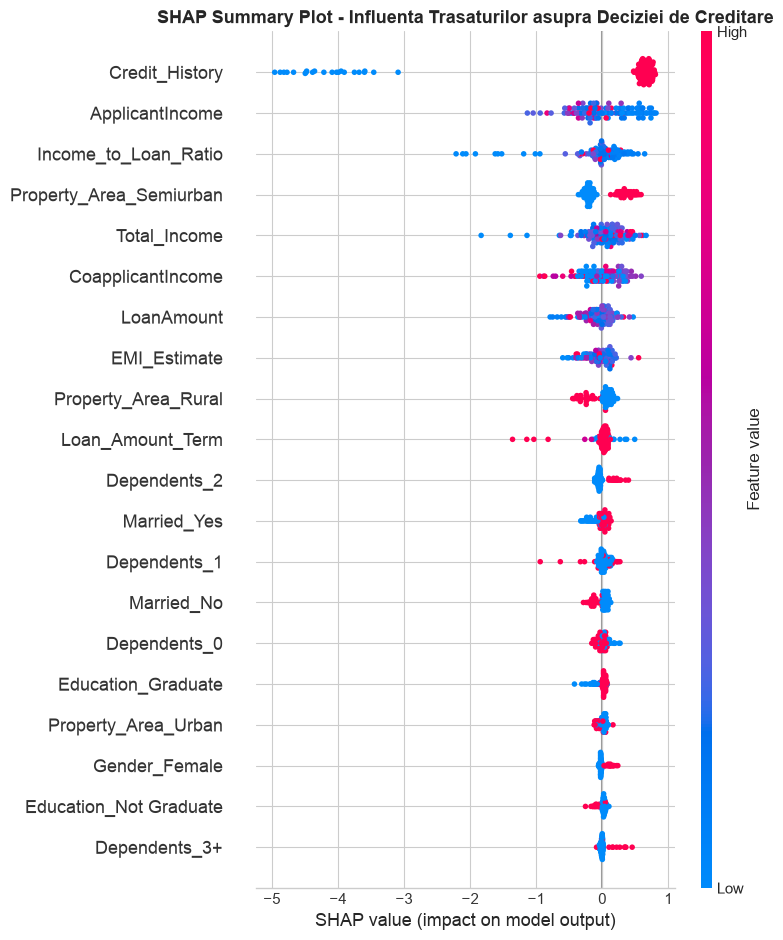

In [14]:
# Explicabilitate SHAP (Shapley Additive Explanations)
# Preprocesam datele pentru TreeExplainer
X_train_trans = final_model_pipe.named_steps["prep"].transform(X_train_raw)
X_test_trans = final_model_pipe.named_steps["prep"].transform(X_test_raw)

cat_encoder = final_model_pipe.named_steps["prep"].named_steps["preproc"].named_transformers_["cat"].named_steps["encoder"]
encoded_features = num_features + list(cat_encoder.get_feature_names_out(cat_features))

cat_model_raw = final_model_pipe.named_steps["clf"]
explainer = shap.TreeExplainer(cat_model_raw)
shap_vals = explainer.shap_values(X_test_trans)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals, X_test_trans, feature_names=encoded_features, show=False)
plt.title("SHAP Summary Plot - Influenta Trasaturilor asupra Deciziei de Creditare", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


In [ ]:
# Salvare model final complet in models/best_classification_model.joblib
joblib.dump(final_model_pipe, "models/best_classification_model.joblib")
print("Modelul de clasificare a fost salvat cu succes in: models/best_classification_model.joblib")
print("Acest model este gata de utilizat in aplicatia Streamlit pentru predictii manuale si batch CSV.")

Modelul de clasificare a fost salvat cu succes in: models/best_classification_model.joblib
Acest model este gata de utilizat in aplicatia Streamlit pentru predictii manuale si batch CSV.
